# Ejercicio k-Nearest Neighbor

## App Reviews
En este ejercicio vas a trabajar con una base de datos de reviews de una aplicación. Entre los datos podemos encontrar el texto de la review, las estrellas, así como el sentimiento del comentario (si es algo bueno o malo).

El objetivo es montar un algoritmo de clasificación que prediga el rating, en función del sentimiento del comentario y la cantidad de palabras empleadas en el mismo. Para ello tendrás que utilizar un algoritmo de tipo KNN.

## Importamos las librerías que vamos a utilizar

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Leemos nuestro archivo de entrada `reviews_sentiment`

In [2]:
pd.set_option('max_colwidth', None)

In [ ]:
# lee los datos de 'data/reviews_sentiment.csv'
# df

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,"Hola desde hace algo más de un mes me pone sin conexión y no sale nada, antes me funcionaba correctamente.",23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas complicada de usar hay gente cambiandosevpor esevmotivo gracias,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784
...,...,...,...,...,...,...,...
252,Muy buena aplicacion,Muy buena genial,3,positive,positive,5,2.814818
253,Buena,Genial,1,positive,positive,5,2.924393
254,Wuau,Genial,1,positive,positive,5,2.924393
255,Muy buena,Genial,1,positive,positive,5,2.924393


In [3]:
df = pd.read_csv('data/reviews_sentiment.csv', sep=';')
df

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,"Hola desde hace algo más de un mes me pone sin conexión y no sale nada, antes me funcionaba correctamente.",23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas complicada de usar hay gente cambiandosevpor esevmotivo gracias,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784
...,...,...,...,...,...,...,...
252,Muy buena aplicacion,Muy buena genial,3,positive,positive,5,2.814818
253,Buena,Genial,1,positive,positive,5,2.924393
254,Wuau,Genial,1,positive,positive,5,2.924393
255,Muy buena,Genial,1,positive,positive,5,2.924393


Para facilitar el ejercicio, las columnas que utilizaremos serán: wordcount con la cantidad de palabras utilizadas y sentimentValue con un valor entre -4 y 4 que indica si el comentario fue valorado como positivo o negativo

Nuestras etiquetas, serán las estrellas que dieron los usuarios a la app, que son valores discretos del 1 al 5

## Rápidas visualizaciones y análisis
Al menos realiza un análisis univariante y representa la distribución del rating. Realiza otras visualizaciones para ver la relación de tus datos.

In [ ]:
# haz un info del df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    object 
 1   Review Text     257 non-null    object 
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    object 
 4   textSentiment   257 non-null    object 
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), object(4)
memory usage: 14.2+ KB


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    str    
 1   Review Text     257 non-null    str    
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    str    
 4   textSentiment   257 non-null    str    
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), str(4)
memory usage: 29.3 KB


In [ ]:
# haz un descrive del df

,wordcount,Star Rating,sentimentValue
count,257.000000,257.000000,257.000000
mean,11.501946,3.420233,0.383849
std,13.159812,1.409531,0.897987
min,1.000000,1.000000,-2.276469
25%,3.000000,3.000000,-0.108144
50%,7.000000,3.000000,0.264091
75%,16.000000,5.000000,0.808384
max,103.000000,5.000000,3.264579


In [5]:
df.describe()

,wordcount,Star Rating,sentimentValue
count,257.000000,257.000000,257.000000
mean,11.501946,3.420233,0.383849
std,13.159812,1.409531,0.897987
min,1.000000,1.000000,-2.276469
25%,3.000000,3.000000,-0.108144
50%,7.000000,3.000000,0.264091
75%,16.000000,5.000000,0.808384
max,103.000000,5.000000,3.264579


array([[<Axes: title={'center': 'wordcount'}>,
        <Axes: title={'center': 'Star Rating'}>],
       [<Axes: title={'center': 'sentimentValue'}>, <Axes: >]],
      dtype=object)

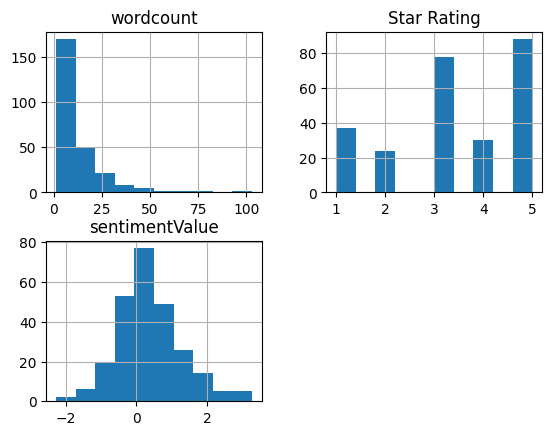

In [ ]:
# calcula los histogramas del df

array([[<Axes: title={'center': 'wordcount'}>,
        <Axes: title={'center': 'Star Rating'}>],
       [<Axes: title={'center': 'sentimentValue'}>, <Axes: >]],
      dtype=object)

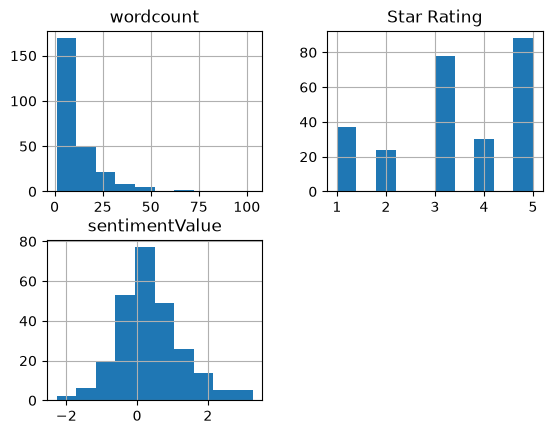

In [6]:
df.hist()

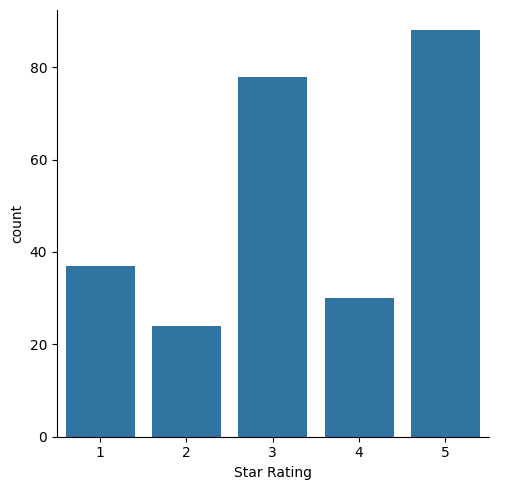

In [ ]:
# haz un catplot del star rating

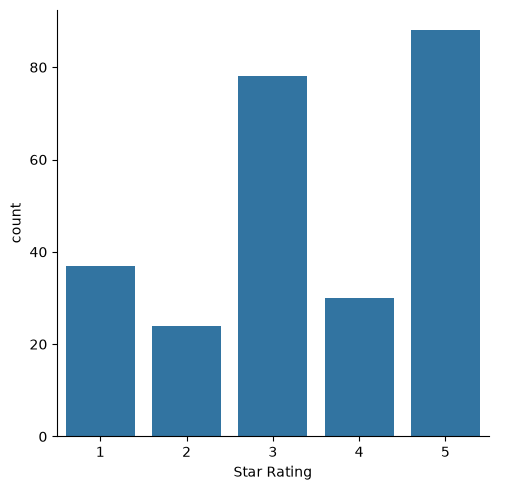

In [7]:
sns.catplot(x="Star Rating", data=df, kind='count')

In [ ]:
# haz un value counts del star rating

Star Rating
5    0.342412
3    0.303502
1    0.143969
4    0.116732
2    0.093385
Name: proportion, dtype: float64

In [9]:
df['Star Rating'].value_counts(normalize=True)

Star Rating
5    0.342412
3    0.303502
1    0.143969
4    0.116732
2    0.093385
Name: proportion, dtype: float64

In [9]:
# imblearn

<Axes: >

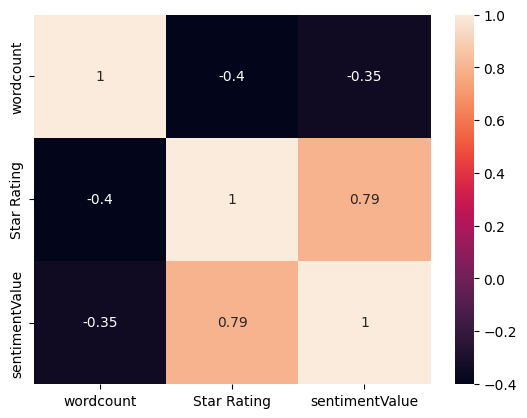

In [ ]:
# haz un heatmap de la matriz de correlación

<Axes: >

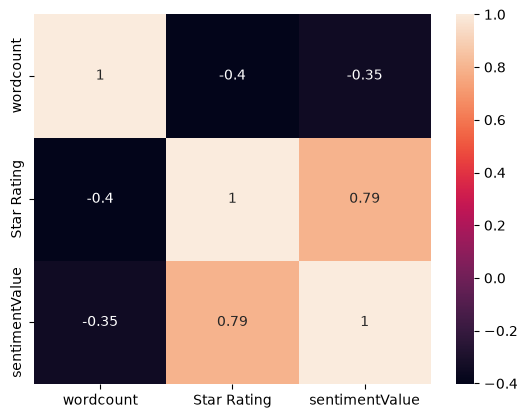

In [10]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## Preparamos el dataset
Divide en train/test y escala las features en el rango [0, 1].

In [ ]:
#
# X es wordcount y sentimentValue
# y es Star Rating

# haz un train_test_split
# muestra los shape de X train, X test, y train, y test



(205, 2)
(52, 2)
(205,)
(52,)


In [11]:
from sklearn.model_selection import train_test_split

X = df[['wordcount', 'sentimentValue']]
y = df['Star Rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(205, 2)
(52, 2)
(205,)
(52,)


In [12]:
# importa standardscaler y minmaxscaler
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
# haz un minmaxscaler y úsalo con X train y con Xtest


# calcula los mínimos y máximos en X train y en X test


1.0
0.0
0.9325760278023711
-0.0982228016602878


In [13]:
# haz un minmaxscaler y úsalo con X train y con Xtest
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# calcula los mínimos y máximos en X train y en X test

print("Mínimo de X_train:", X_train_scaled.min())
print("Máximo de X_train:", X_train_scaled.max())

print("Mínimo de X_test:", X_test_scaled.min())
print("Máximo de X_test:", X_test_scaled.max())

Mínimo de X_train: 0.0
Máximo de X_train: 1.0
Mínimo de X_test: -0.0982228016602878
Máximo de X_test: 0.9325760278023711


In [ ]:
# equivalente pero con StandardScaler

1.9496599456832016e-17
0.9999999999999999
0.00952085195612695
1.128192754031885


In [14]:
standard = StandardScaler()

X_train_scaled_s = standard.fit_transform(X_train)
X_test_scaled_s = standard.transform(X_test)

# calcula los mínimos y máximos en X train y en X test

print("Mínimo de X_train:", X_train_scaled_s.min())
print("Máximo de X_train:", X_train_scaled_s.max())

print("Mínimo de X_test:", X_test_scaled_s.min())
print("Máximo de X_test:", X_test_scaled_s.max())

Mínimo de X_train: -2.510174849807028
Máximo de X_train: 7.1466023818326105
Mínimo de X_test: -3.0805105378878506
Máximo de X_test: 5.044437096003652


## Creamos el Modelo
Entrena con un KNN y evalúa el error en train y en test

In [15]:
# importa el knn clasiffier
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
# inicialízalo y entrénalo con X train, y train

KNeighborsClassifier()

In [16]:
knn = KNeighborsClassifier()

knn.fit(X_train_scaled_s, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](5,)","[1,2,3,4,5]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Evalúa tu modelo

In [17]:
# importa el accuracy score, la matriz de confusión, la matriz de confusión multicategoría y el classification report

from sklearn.metrics import accuracy_score, confusion_matrix, multilabel_confusion_matrix, classification_report

In [ ]:
# predice con X test escalado
# calcula el accuracy en test y la matriz de confusión en test



accuracy_score 0.8653846153846154
confusion_matrix
 [[ 9  1  0  0  0]
 [ 0  2  0  0  0]
 [ 2  1 11  0  0]
 [ 0  1  1  5  0]
 [ 0  0  1  0 18]]


In [18]:
y_train_pred = knn.predict(X_train_scaled_s)
y_test_pred = knn.predict(X_test_scaled_s)

acc_test = accuracy_score(y_test, y_test_pred)
cm = confusion_matrix(y_test, y_test_pred)

print("accuracy_score:", acc_test)
print("confusion_matrix:", cm)

accuracy_score: 0.8653846153846154
confusion_matrix: [[ 9  1  0  0  0]
 [ 0  2  0  0  0]
 [ 2  1 11  0  0]
 [ 0  1  1  5  0]
 [ 0  0  1  0 18]]


In [ ]:

# calcula la multilabel confusion matriz en test

array([[[40,  2],
        [ 1,  9]],

       [[47,  3],
        [ 0,  2]],

       [[36,  2],
        [ 3, 11]],

       [[45,  0],
        [ 2,  5]],

       [[33,  0],
        [ 1, 18]]])

In [19]:
from sklearn.metrics import multilabel_confusion_matrix

mcm = multilabel_confusion_matrix(y_test, y_test_pred)

print(mcm)

[[[40  2]
  [ 1  9]]

 [[47  3]
  [ 0  2]]

 [[36  2]
  [ 3 11]]

 [[45  0]
  [ 2  5]]

 [[33  0]
  [ 1 18]]]


In [ ]:
# calcula el classification report en test

              precision    recall  f1-score   support

           1       0.82      0.90      0.86        10
           2       0.40      1.00      0.57         2
           3       0.85      0.79      0.81        14
           4       1.00      0.71      0.83         7
           5       1.00      0.95      0.97        19

    accuracy                           0.87        52
   macro avg       0.81      0.87      0.81        52
weighted avg       0.90      0.87      0.87        52



In [20]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           1       0.82      0.90      0.86        10
           2       0.40      1.00      0.57         2
           3       0.85      0.79      0.81        14
           4       1.00      0.71      0.83         7
           5       1.00      0.95      0.97        19

    accuracy                           0.87        52
   macro avg       0.81      0.87      0.81        52
weighted avg       0.90      0.87      0.87        52



In [ ]:

# predice los puntos originales [[10,3],[3,-2]]

c:\Users\Alberto Romero\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([5, 1])

In [21]:
puntos_originales = np.array([[10, 3], [3, -2]])

puntos_originales_scaled = scaler.transform(puntos_originales)

prediccion = knn.predict(puntos_originales_scaled)

print(prediccion)

[4 3]


c:\Users\bgran\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


## ¿Cómo obtener el mejor valor de k? Crea y evalúa nuevos modelos
¿Qué valor de k maximiza el accuracy? Representa todas las iteraciones en un scatterplot -> k vs accuracy

In [ ]:
# sin usar gridsearchcv, prueba valores de k entre 1 y 30
# usa un bucle for, entrena el modelo y calcula el score en test



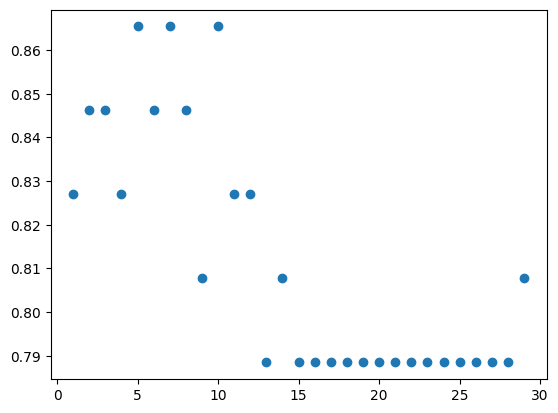

In [ ]:
# con un scatter plot pinta para cada k su score en test

In [ ]:
# EXTRA

# usa pipeline y gridsearchcv

# importa los módulos

In [ ]:
# Haz un pipeline con pasos: minmaxscaler y luego knn classifier



In [ ]:
# hiperparámetros

params = {
    'scaler': [MinMaxScaler(), StandardScaler(), None],
    'classifier__n_neighbors': np.arange(2,15),
    'classifier__weights': ['uniform', 'distance']
}

In [27]:
gs_pipe = GridSearchCV(pipe, params, cv=5, scoring='accuracy', verbose=2)
gs_pipe.fit(X_train, y_train)
print(gs_pipe.best_estimator_)
print(gs_pipe.best_params_)
print(gs_pipe.best_score_)

Fitting 5 folds for each of 78 candidates, totalling 390 fits
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=MinMaxScaler(); total time=   0.0s
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=MinMaxScaler(); total time=   0.0s
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=MinMaxScaler(); total time=   0.0s
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=MinMaxScaler(); total time=   0.0s
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=MinMaxScaler(); total time=   0.0s
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=StandardScaler(); total time=   0.0s
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=StandardScaler(); total time=   0.0s
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=StandardScaler(); total time=   0.0s
[CV] END classifier__n_neighbors=2, classifier__weights=uniform, scaler=Stan

In [28]:
h_model = gs_pipe.best_estimator_
h_model

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('classifier', KNeighborsClassifier(n_neighbors=np.int64(7)))])

In [29]:
h_model.fit(X_train, y_train)
y_pred = h_model.predict(X_test)
print("accuracy_score", accuracy_score(y_test, y_pred))

accuracy_score 0.8269230769230769


In [30]:
h_model['classifier']

KNeighborsClassifier(n_neighbors=np.int64(7))

In [31]:
h_model['scaler']

MinMaxScaler()

## Predice con nuevos datos.
Ejemplo: supongamos que nos llega una review de 5 palabras y sentimiento 1

In [32]:
h_model

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('classifier', KNeighborsClassifier(n_neighbors=np.int64(7)))])

In [ ]:
# predice el punto [5,1]

c:\Users\Alberto Romero\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


array([5])